In [1]:
import matplotlib.pyplot as plt
import torch
import numpy as np
from PIL import Image
import torchvision.transforms as transforms

In [15]:
model = torch.hub.load('yvanyin/metric3d', 'metric3d_vit_small', pretrain=True)

image_path = '/home/yancheng/code/wsg/output/test_dataset_results/human_signer_480/crop_frame/00000001.jpg'
image = Image.open(image_path).convert('RGB')  # Ensure 3-channel RGB

# Convert to tensor
transform = transforms.ToTensor()  # Converts to [0, 1] float tensor of shape (C, H, W)
image_tensor = transform(image)    # torch.Size([3, H, W])
image_tensor = image_tensor.unsqueeze(0)  # torch.Size([1, 3, H, W])

model.to('cuda')
image_tensor = image_tensor.to('cuda')

pred_depth, confidence, output_dict = model.inference({'input': image_tensor})
pred_normal = output_dict['prediction_normal'][:, :3, :, :] # only available for Metric3Dv2 i.e., ViT models
normal_confidence = output_dict['prediction_normal'][:, 3, :, :] # see https://arxiv.org/abs/2109.09881 for details



Using cache found in /home/yancheng/.cache/torch/hub/yvanyin_metric3d_main


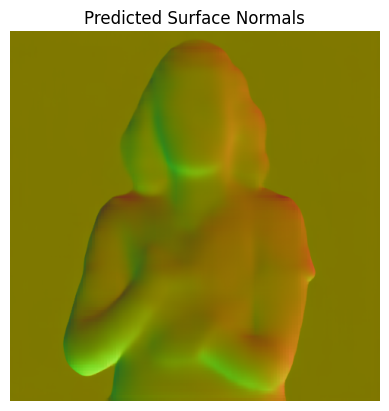

In [16]:
# Get the normal tensor and move to CPU if needed
normal_tensor = pred_normal[0].detach().cpu()  # Shape: [3, H, W]

# Convert to NumPy and normalize from [-1, 1] to [0, 1]
normal_np = normal_tensor.permute(1, 2, 0).numpy()  # Shape: [H, W, 3]
normal_np = (normal_np + 1.0) / 2.0  # Normalize to [0, 1] for visualization

# Clip to [0, 1] and plot
normal_np = np.clip(normal_np, 0, 1)

plt.imshow(normal_np)
plt.axis('off')
plt.title("Predicted Surface Normals")
plt.show()

(480, 480)


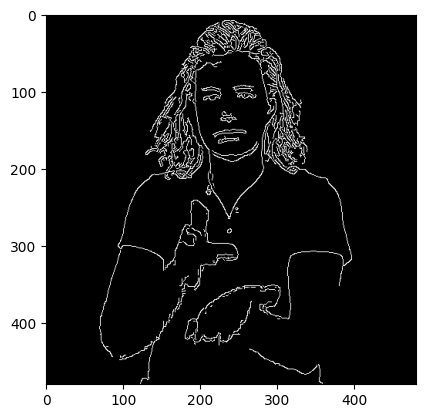

In [33]:
import cv2

# Load RGB image
rgb_image = cv2.imread('/home/yancheng/code/wsg/output/test_dataset_results/human_signer_480/crop_frame/00000001.jpg')  # BGR by default if using cv2.imread
rgb_image = cv2.cvtColor(rgb_image, cv2.COLOR_BGR2RGB)  # If needed

# Convert to grayscale
gray_image = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2GRAY)

# Apply Canny edge detection
edges = cv2.Canny(gray_image, threshold1=50, threshold2=150)
print(edges.shape)
plt.imshow(edges, cmap='gray')
plt.show()

(480, 480)


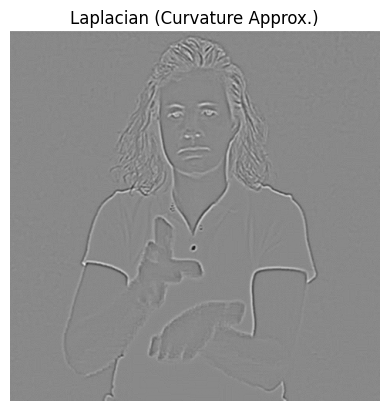

In [6]:
# Load RGB image
rgb_image = cv2.imread('/home/yancheng/code/wsg/output/test_dataset_results/human_signer_480/crop_frame/00000001.jpg')  # BGR by default if using cv2.imread
rgb_image = cv2.cvtColor(rgb_image, cv2.COLOR_BGR2RGB)  # If needed

# Convert to grayscale
gray_image = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2GRAY)

# Optional: Smooth the image
gray_blur = cv2.GaussianBlur(gray_image, (5, 5), 1)

# Apply Laplacian to approximate curvature
laplacian = cv2.Laplacian(gray_blur, cv2.CV_64F)

# Normalize for visualization
laplacian_norm = cv2.normalize(laplacian, None, 0, 255, cv2.NORM_MINMAX)
laplacian_vis = laplacian_norm.astype(np.uint8)

print(laplacian_vis.shape)

# Show result
plt.imshow(laplacian_vis, cmap='gray')
plt.title('Laplacian (Curvature Approx.)')
plt.axis('off')
plt.show()

In [7]:
import cv2 as cv
import ptlflow
from ptlflow.utils import flow_utils
from ptlflow.utils.io_adapter import IOAdapter

/home/yancheng/miniconda3/envs/wsg/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/yancheng/miniconda3/envs/wsg/lib/python3.10/site-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


[!!alt_cuda_corr is not compiled!!]


In [34]:
# model = ptlflow.get_model('dpflow', ckpt_path='things')
# model.to('cuda')
# model = ptlflow.get_model('raft_small', ckpt_path='things')
model = ptlflow.get_model('flownetsd', ckpt_path='things')

2025-07-20 00:14:59.915 | INFO     | ptlflow:restore_model:283 - Restored model state from checkpoint: things


2
torch.Size([1, 1, 2, 480, 480])


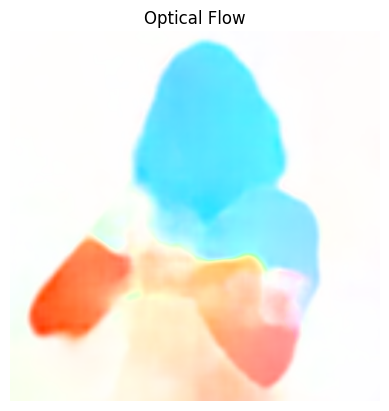

In [36]:
import os
image_base = '/home/yancheng/code/wsg/output/test_dataset_results/human_signer_480/crop_frame'
image_names = os.listdir(image_base)
image_names = sorted(image_names)
image_names = image_names[1:3]
image_paths = [os.path.join(image_base, name) for name in image_names]
images = [cv.imread(path) for path in image_paths]
print(len(images))
# A helper to manage inputs and outputs of the model
# io_adapter = IOAdapter(
#             output_stride=model.output_stride,
#             input_size=images[0].shape[:2],
#             target_size=images[0].shape[:2],
#             cuda=False,
#             fp16=False,
#     )
# cuda=torch.cuda.is_available(),
# inputs is a dict {'images': torch.Tensor}
# The tensor is 5D with a shape BNCHW. In this case, it will have the shape:
# (1, 2, 3, H, W)

# A helper to manage inputs and outputs of the model
io_adapter = IOAdapter(model, images[0].shape[:2])

# inputs is a dict {'images': torch.Tensor}
# The tensor is 5D with a shape BNCHW. In this case, it will have the shape:
# (1, 2, 3, H, W)
inputs = io_adapter.prepare_inputs(images)

# Forward the inputs through the model
predictions = model(inputs)

# The output is a dict with possibly several keys,
# but it should always store the optical flow prediction in a key called 'flows'.
flows = predictions['flows']

# flows will be a 5D tensor BNCHW.
# This example should print a shape (1, 1, 2, H, W).
print(flows.shape)

# Create an RGB representation of the flow to show it on the screen
flow_rgb = flow_utils.flow_to_rgb(flows)
# Make it a numpy array with HWC shape
flow_rgb = flow_rgb[0, 0].permute(1, 2, 0)
flow_rgb_npy = flow_rgb.detach().cpu().numpy()
# OpenCV uses BGR format
flow_bgr_npy = cv.cvtColor(flow_rgb_npy, cv.COLOR_RGB2BGR)

flow_rgb_for_plt = cv.cvtColor(flow_bgr_npy, cv.COLOR_BGR2RGB)
plt.imshow(flow_rgb_for_plt)
plt.title("Optical Flow")
plt.axis('off')
plt.show()
